In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns 

In [2]:
#1 read csv 
DATA_PATH = "data/opsd_germany_daily.csv"
data = pd.read_csv(DATA_PATH,index_col=0,parse_dates=True)
data.head()

,Consumption,Wind,Solar,Wind+Solar
Date,,,,
2006-01-01,1069.184,NaN,NaN,NaN
2006-01-02,1380.521,NaN,NaN,NaN
2006-01-03,1442.533,NaN,NaN,NaN
2006-01-04,1457.217,NaN,NaN,NaN
2006-01-05,1477.131,NaN,NaN,NaN


In [3]:
data["Year"] = data.index.year
data["Month"] = data.index.month
data["Weekday"] = data.index.day_name()
data.head()

,Consumption,Wind,Solar,Wind+Solar,Year,Month,Weekday
Date,,,,,,,
2006-01-01,1069.184,NaN,NaN,NaN,2006,1,Sunday
2006-01-02,1380.521,NaN,NaN,NaN,2006,1,Monday
2006-01-03,1442.533,NaN,NaN,NaN,2006,1,Tuesday
2006-01-04,1457.217,NaN,NaN,NaN,2006,1,Wednesday
2006-01-05,1477.131,NaN,NaN,NaN,2006,1,Thursday


In [ ]:
#2. Time based indexing
# data.loc["2006-01-01":"2006-01-31"]
#same with
data.loc["2006-01"]

,Consumption,Wind,Solar,Wind+Solar,Year,Month,Weekday
Date,,,,,,,
2006-01-01,1069.184,NaN,NaN,NaN,2006,1,Sunday
2006-01-02,1380.521,NaN,NaN,NaN,2006,1,Monday
2006-01-03,1442.533,NaN,NaN,NaN,2006,1,Tuesday
2006-01-04,1457.217,NaN,NaN,NaN,2006,1,Wednesday
2006-01-05,1477.131,NaN,NaN,NaN,2006,1,Thursday
2006-01-06,1403.427,NaN,NaN,NaN,2006,1,Friday
2006-01-07,1300.287,NaN,NaN,NaN,2006,1,Saturday
2006-01-08,1207.985,NaN,NaN,NaN,2006,1,Sunday
2006-01-09,1529.323,NaN,NaN,NaN,2006,1,Monday


<Axes: xlabel='Date'>

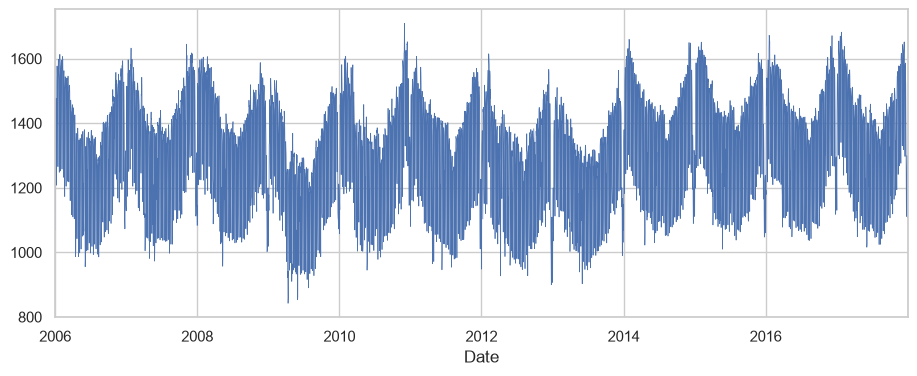

In [28]:
#3. Visualize time series data 
sns.set_theme(style="whitegrid")
data["Consumption"].plot(figsize=(11,4),linewidth = 0.5)


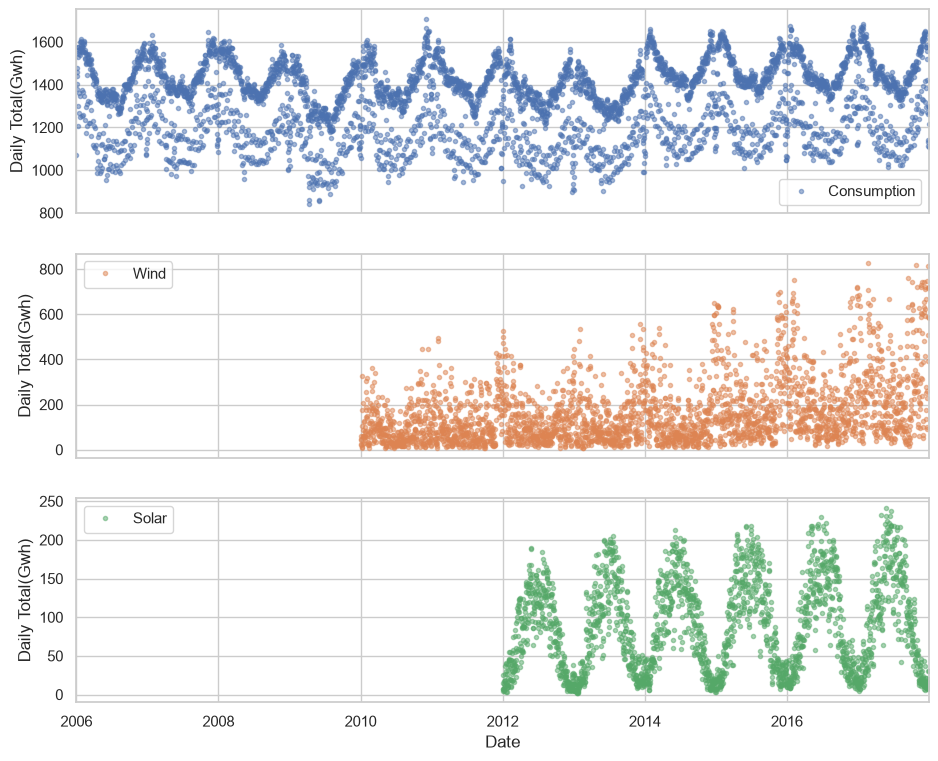

In [37]:
data_col = ["Consumption","Wind","Solar"]
axes = data[data_col].plot(marker=".",alpha=0.5,linestyle="None",figsize=(11,9),subplots=True)
for ax in axes:
    ax.set_ylabel("Daily Total(Gwh)")
plt.show()

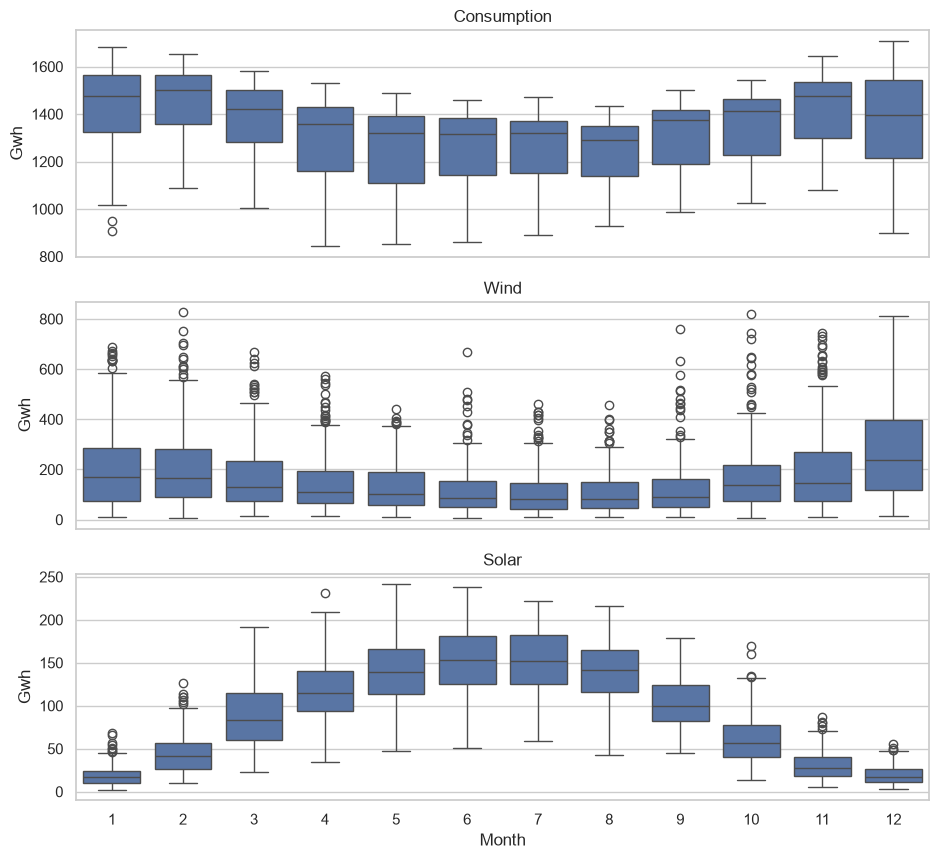

In [46]:
#4. Seasonality
fig,axes = plt.subplots(3,1,figsize = (11,10),sharex = True)
for name,ax in zip(["Consumption","Wind","Solar"],axes):
    sns.boxplot(data,x = "Month",y = name,ax = ax)
    ax.set_ylabel("Gwh")
    ax.set_title(name)
    if ax != axes[-1]:
        ax.set_xlabel("")



In [58]:
#5. Frequencies
time_sample = pd.to_datetime(["2013-02-03", "2013-02-06", "2013-02-08"])
consump_sample = data.loc[time_sample,["Consumption"]].copy()
consump_sample = consump_sample.asfreq("D").ffill()
consump_sample

,Consumption
2013-02-03,1109.639
2013-02-04,1109.639
2013-02-05,1109.639
2013-02-06,1451.449
2013-02-07,1451.449
2013-02-08,1433.098


In [8]:
#6. resampling 
data_col = data[["Consumption","Wind","Solar","Wind+Solar"]]
data_resample = data_col.resample("W").mean()
data_resample


,Consumption,Wind,Solar,Wind+Solar
Date,,,,
2006-01-01,1069.184000,NaN,NaN,NaN
2006-01-08,1381.300143,NaN,NaN,NaN
2006-01-15,1486.730286,NaN,NaN,NaN
2006-01-22,1490.031143,NaN,NaN,NaN
2006-01-29,1514.176857,NaN,NaN,NaN
...,...,...,...,...
2017-12-03,1536.236314,284.334286,18.320857,302.655143
2017-12-10,1554.824946,636.514714,16.440286,652.955000
2017-12-17,1543.856889,442.531857,18.143714,460.675571


In [9]:
data_resample_manual = data_col.resample("YE").sum(min_count=360)
data_resample_manual

,Consumption,Wind,Solar,Wind+Solar
Date,,,,
2006-12-31,489068.53600,NaN,NaN,NaN
2007-12-31,496631.84700,NaN,NaN,NaN
2008-12-31,495570.87600,NaN,NaN,NaN
2009-12-31,459737.42800,NaN,NaN,NaN
2010-12-31,488588.70000,35911.777,NaN,NaN
2011-12-31,484814.08600,44032.951,NaN,NaN
2012-12-31,469574.75400,45862.667,27887.332,73749.999
2013-12-31,463336.85300,47197.832,29559.780,76697.443
2014-12-31,504164.82100,51107.672,32498.307,83370.502


In [11]:
#7 Rolling
# Specify the feature columns to analyze
data_columns = ['Consumption', 'Wind', 'Solar', 'Wind+Solar']

# Compute the centered 7-day rolling mean
opsd_7d = data[data_columns].rolling(window=7, center=True).mean()

# Preview the first 10 rows
opsd_7d.head(10)

,Consumption,Wind,Solar,Wind+Solar
Date,,,,
2006-01-01,NaN,NaN,NaN,NaN
2006-01-02,NaN,NaN,NaN,NaN
2006-01-03,NaN,NaN,NaN,NaN
2006-01-04,1361.471429,NaN,NaN,NaN
2006-01-05,1381.300143,NaN,NaN,NaN
2006-01-06,1402.557571,NaN,NaN,NaN
2006-01-07,1421.754429,NaN,NaN,NaN
2006-01-08,1438.891429,NaN,NaN,NaN
2006-01-09,1449.769857,NaN,NaN,NaN


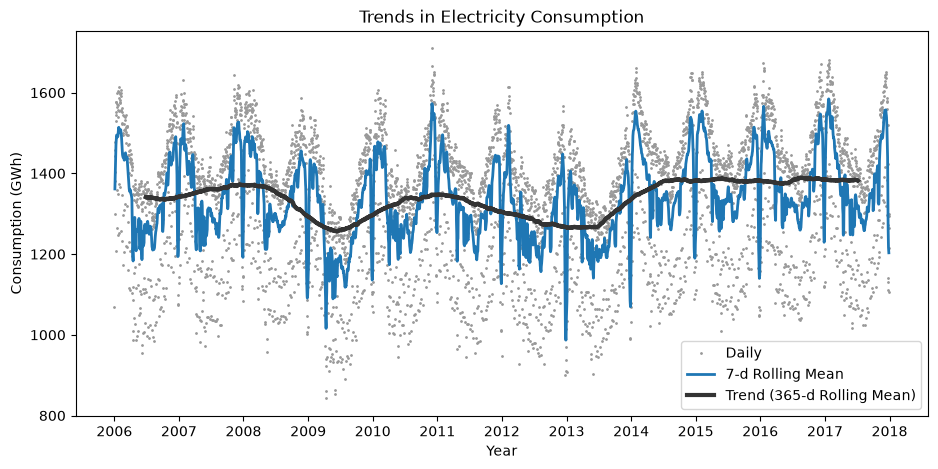

In [12]:
#8. Trend
import matplotlib.dates as mdates

# Compute the 365-day rolling mean (min_periods=360 handles isolated missing values)
opsd_365d = data[data_columns].rolling(
    window=365, center=True, min_periods=360
).mean()

# Initialize the figure and axes
fig, ax = plt.subplots(figsize=(11, 5))

# Plot daily totals as light gray points (captures raw variations)
ax.plot(data['Consumption'], marker='.', markersize=2, color='0.6', 
        linestyle='None', label='Daily')

# Plot 7-day rolling mean (filters out weekly seasonality)
ax.plot(opsd_7d['Consumption'], linewidth=2, label='7-d Rolling Mean')

# Plot 365-day rolling mean (filters out annual seasonality to reveal long-term trend)
ax.plot(opsd_365d['Consumption'], color='0.2', linewidth=3, 
        label='Trend (365-d Rolling Mean)')

# Set yearly x-axis tick locators and styling
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.set_xlabel('Year')
ax.set_ylabel('Consumption (GWh)')
ax.set_title('Trends in Electricity Consumption')
ax.legend()

plt.show()

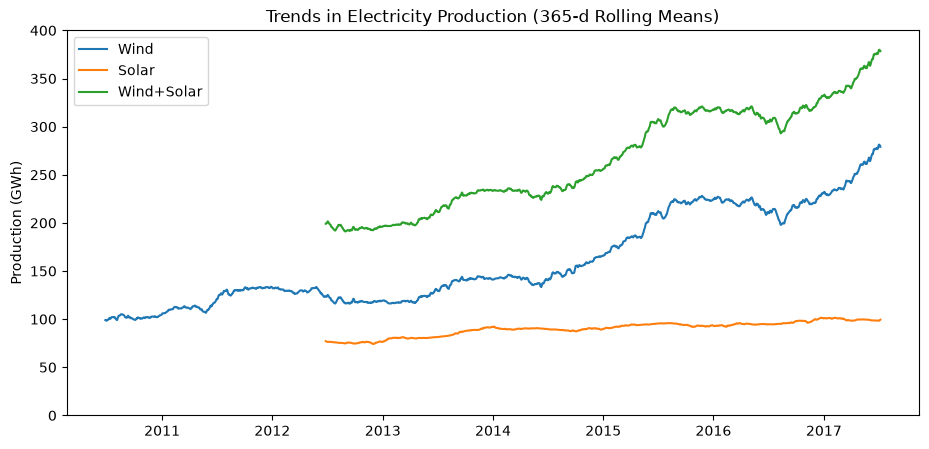

In [13]:
# Initialize figure for renewable energy production trends
fig, ax = plt.subplots(figsize=(11, 5))

# Plot 365-day rolling means for Wind, Solar, and Wind+Solar
for col_name in ['Wind', 'Solar', 'Wind+Solar']:
    ax.plot(opsd_365d[col_name], label=col_name)

# Set x-ticks to yearly intervals, adjust y-axis range, and add annotations
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.set_ylim(0, 400)
ax.set_ylabel('Production (GWh)')
ax.set_title('Trends in Electricity Production (365-d Rolling Means)')
ax.legend()

plt.show()